# Steam Game Recommender — Check-in 2:

**DSAN 6600 | Existing-user personalized top-N recommendations**

**Research question:** Does the neural model improve recommendations for *existing users* relative to popularity alone?

## 1. Configuration and environment

In [1]:
#Import packages
from pathlib import Path
from collections import defaultdict
import copy
import json
import os
import random
import time
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

#Setup
SEED = 42
MIN_POSITIVES = 15
N_VAL_POSITIVES = 5
N_TEST_POSITIVES = 5
#Set to None to use every training positive
MAX_TRAIN_POSITIVES_PER_USER = 1000   
#Sampled unowned pairs per training positive
NEGATIVE_RATIO = 2                   
EMBEDDING_DIM = 32
HIDDEN_DIMS = (64, 32)
DROPOUT = 0.10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-6
BATCH_SIZE = 2048
EPOCHS = 5
PATIENCE = 2
TOP_K = 10
#Evaluated with five validation positives
VAL_NEGATIVE_CANDIDATES = 1000    
#Fast initial test; *sampled-candidate* metrics
TEST_NEGATIVE_CANDIDATES = 2000     
#Set True to assess every unowned candidate (slower)
RUN_FULL_CATALOG_TEST = True       
INFERENCE_BATCH_SIZE = 16384

#Set file paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DATA_DIR = PROJECT_ROOT / 'data' / 'raw'
USER_GAMES_PATH = RAW_DATA_DIR / 'user_games.parquet'
GAMES_PATH = RAW_DATA_DIR / 'games.parquet'
RESULTS_DIR = PROJECT_ROOT / 'results'
MODELS_DIR = PROJECT_ROOT / 'models'
RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

assert USER_GAMES_PATH.exists(), f'Not found: {USER_GAMES_PATH}'
assert GAMES_PATH.exists(), f'Not found: {GAMES_PATH}'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')
    torch.set_num_threads(min(4, os.cpu_count() or 4))

print('Project:', PROJECT_ROOT)
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
print('User data:', USER_GAMES_PATH)

Project: /Users/robertgeorge/Desktop/DSAN Files/6600/dsan6600-finalproject
PyTorch: 2.11.0 | Device: cpu
User data: /Users/robertgeorge/Desktop/DSAN Files/6600/dsan6600-finalproject/data/raw/user_games.parquet


## 2. Load and encode existing user–game interactions
- The EDA found no duplicate `(steamid, appid)` pairs, but we still collapse any duplicates if present.
- `steamid` is a **string**, not a floating-point numeric ID.
- DuckDB assigns compact integer user IDs before loading the large table into pandas; we load **only the three columns required for the model**.
- All observed ownership, including zero-playtime games, is preserved for candidate filtering.

In [2]:
con = duckdb.connect()
user_path = str(USER_GAMES_PATH).replace("'", "''")
games_path = str(GAMES_PATH).replace("'", "''")

user_lookup = con.execute(f"""
    SELECT DISTINCT steamid
    FROM read_parquet('{user_path}')
    WHERE steamid IS NOT NULL
    ORDER BY steamid
""").df()
user_lookup['user_idx'] = np.arange(len(user_lookup), dtype=np.int32)
con.register('user_lookup', user_lookup)

interactions = con.execute(f"""
    SELECT u.user_idx::INTEGER AS user_idx,
           ug.appid::INTEGER AS appid,
           COALESCE(ug.playtime_forever, 0)::INTEGER AS playtime_forever
    FROM read_parquet('{user_path}') AS ug
    INNER JOIN user_lookup AS u ON ug.steamid = u.steamid
    WHERE ug.appid IS NOT NULL
""").df()

num_duplicates = int(interactions.duplicated(['user_idx', 'appid']).sum())
if num_duplicates:
    print('Collapsing duplicate user-game pairs:', f'{num_duplicates:,}')
    interactions = (interactions.groupby(['user_idx', 'appid'], as_index=False)
                    ['playtime_forever'].max())

all_appids = np.sort(interactions['appid'].unique().astype(np.int64))
n_users = len(user_lookup)
n_items = len(all_appids)

owned_by_user = [np.empty(0, dtype=np.int32) for _ in range(n_users)]
positive_by_user = [np.empty(0, dtype=np.int32) for _ in range(n_users)]

for u, group in interactions.groupby('user_idx', sort=False):
    ids = np.searchsorted(all_appids, group['appid'].to_numpy(dtype=np.int64)).astype(np.int32)
    played = group['playtime_forever'].to_numpy() > 0
    owned_by_user[int(u)] = np.unique(ids)
    positive_by_user[int(u)] = np.unique(ids[played])

summary = pd.DataFrame({
    'user_idx': np.arange(n_users),
    'owned': [len(v) for v in owned_by_user],
    'played': [len(v) for v in positive_by_user],
})
print(f'Users: {n_users:,} | Games: {n_items:,} | Unique observed pairs: {len(interactions):,}')
print(f'Positive pairs: {summary["played"].sum():,} | Duplicate pairs merged: {num_duplicates:,}')
display(summary[['owned', 'played']].describe(percentiles=[0.25, 0.5, 0.75, 0.9]))

# The full interaction dataframe is no longer needed.
del interactions

Users: 786 | Games: 49,830 | Unique observed pairs: 11,285,290
Positive pairs: 4,488,063 | Duplicate pairs merged: 0


,owned,played
count,786.000000,786.000000
mean,14357.875318,5710.003817
std,4603.727582,3535.226225
min,4455.000000,88.000000
25%,11361.000000,3223.000000
50%,12674.000000,6132.000000
75%,15660.750000,7377.750000
90%,20683.500000,8892.000000
max,40125.000000,32186.000000


## 3. Deduplicated game-name lookup

Game metadata is used **only to display titles**, not as input to Check-in 2's neural model. Some game metadata rows may repeat an `appid`; grouping by ID avoids artificially multiplying rows during a join. Genre tags (including `Indie`) are intentionally **not model features here**; gameplay-genre treatment belongs in the EDA revision / Check-in 3.

In [3]:
name_rows = con.execute(f"""
    SELECT appid, MAX(NULLIF(TRIM(name), '')) AS game_name
    FROM read_parquet('{games_path}')
    WHERE appid IS NOT NULL
    GROUP BY appid
""").df()
name_by_appid = dict(zip(name_rows['appid'].astype(np.int64), name_rows['game_name']))

def display_name(item_idx):
    appid = int(all_appids[item_idx])
    title = name_by_appid.get(appid)
    return str(title) if pd.notna(title) and title else f'App {appid}'

print('Metadata title lookup entries:', len(name_by_appid))
print('Example game:', display_name(0))

Metadata title lookup entries: 47753
Example game: Counter-Strike


## 4. Per-user train / validation / test split

For each eligible existing user, we randomly hold out **five distinct played games for validation and five for testing**, then retain the remaining played games as positive training history. `SEED=42` makes this repeatable. Users with fewer than 15 played games are excluded.

**No leakage:** A game's `(user, item)` positive appears in exactly one split. The **negative pool contains only games absent from the user's *entire* observed owned library**, including zero-playtime ownership and both holdouts. Thus we do not invent dislikes for owned-but-unplayed games. We do not use held-out positives during training or to calculate item popularity.

The optional cap of 1,000 training positives per user leaves some known played games unused in training; these remain **excluded as candidates/negatives**. They are not silently relabeled negative.

In [4]:
assert MIN_POSITIVES >= N_VAL_POSITIVES + N_TEST_POSITIVES + 1
split_rng = np.random.default_rng(SEED)
all_item_indices = np.arange(n_items, dtype=np.int32)

eligible_users = np.array([
    u for u in range(n_users)
    if len(positive_by_user[u]) >= MIN_POSITIVES
    and len(owned_by_user[u]) < n_items
], dtype=np.int32)
assert len(eligible_users) > 0, 'No eligible users; check split settings.'

train_by_user, val_by_user, test_by_user = {}, {}, {}
negative_pool_by_user = {}
full_train_counts = {}

for u in eligible_users:
    u = int(u)
    shuffled = split_rng.permutation(positive_by_user[u])
    val = np.sort(shuffled[:N_VAL_POSITIVES])
    test = np.sort(shuffled[N_VAL_POSITIVES:N_VAL_POSITIVES + N_TEST_POSITIVES])
    full_train = shuffled[N_VAL_POSITIVES + N_TEST_POSITIVES:]
    full_train_counts[u] = len(full_train)
    if MAX_TRAIN_POSITIVES_PER_USER is not None and len(full_train) > MAX_TRAIN_POSITIVES_PER_USER:
        full_train = split_rng.choice(full_train, size=MAX_TRAIN_POSITIVES_PER_USER, replace=False)
    train = np.sort(full_train.astype(np.int32))
    pool = np.setdiff1d(all_item_indices, owned_by_user[u], assume_unique=True)

    assert len(np.intersect1d(train, val)) == 0
    assert len(np.intersect1d(train, test)) == 0
    assert len(np.intersect1d(val, test)) == 0
    assert len(np.intersect1d(pool, owned_by_user[u])) == 0

    train_by_user[u], val_by_user[u], test_by_user[u] = train, val, test
    negative_pool_by_user[u] = pool

train_counts = {u: len(v) for u, v in train_by_user.items()}
print('Eligible existing users:', len(eligible_users), 'of', n_users)
print('Training positive pairs used:', f'{sum(train_counts.values()):,}')
print('Validation positive pairs:', f'{len(eligible_users) * N_VAL_POSITIVES:,}')
print('Test positive pairs:', f'{len(eligible_users) * N_TEST_POSITIVES:,}')
print('Training positives omitted by cap:', f'{sum(full_train_counts.values()) - sum(train_counts.values()):,}')
print('Available unowned candidate count per user (min/median/max):',
      min(map(len, negative_pool_by_user.values())),
      int(np.median([len(x) for x in negative_pool_by_user.values()])),
      max(map(len, negative_pool_by_user.values())))

Eligible existing users: 786 of 786
Training positive pairs used: 741,664
Validation positive pairs: 3,930
Test positive pairs: 3,930
Training positives omitted by cap: 3,738,539
Available unowned candidate count per user (min/median/max): 9705 37156 45375


## 5. Popularity baseline (training history only)

Recommend globally most-played games among the **sampled training positives**, filtering each user's owned games. A popularity model cannot personalize beyond filtering. Using the same training-positive sample for both methods keeps this comparison controlled; the cap may affect the absolute popularity rankings.

In [5]:
train_item_indices = np.concatenate([train_by_user[int(u)] for u in eligible_users]).astype(np.int32)
train_user_indices = np.concatenate([
    np.full(len(train_by_user[int(u)]), int(u), dtype=np.int32) for u in eligible_users
])
item_popularity = np.bincount(train_item_indices, minlength=n_items).astype(np.float32)

print('Games with >=1 sampled training positive:', int((item_popularity > 0).sum()))
print('Most popular training games:')
for ix in np.argsort(-item_popularity, kind='stable')[:8]:
    print(f'  {display_name(int(ix))[:55]:55s}  {int(item_popularity[ix]):>4} users')

# Detect test titles with no corresponding training positives (item cold-start).
zero_train_test = sum(int(np.sum(item_popularity[test_by_user[int(u)]] == 0)) for u in eligible_users)
print('Test positives with zero training-positive interactions:', zero_train_test,
      f'({zero_train_test / (len(eligible_users) * N_TEST_POSITIVES):.2%})')

Games with >=1 sampled training positive: 34485
Most popular training games:
  Left 4 Dead 2                                             196 users
  Borderlands 2                                             195 users
  Counter-Strike 2                                          190 users
  Trine Enchanted Edition                                   188 users
  Half-Life 2                                               184 users
  Portal 2                                                  184 users
  Terraria                                                  182 users
  Castle Crashers®                                          182 users
Test positives with zero training-positive interactions: 38 (0.97%)


## 6. Build identical candidate pools for both models

Each user's candidate pool includes **all five target positives plus sampled unowned games** (no other owned games). The same fixed candidates are used for popularity and NCF.

Two evaluation scopes are distinguished:

- **Sampled-candidate validation/test:** fast, interpretable only within the listed candidate count; these metrics are often substantially more optimistic than full-catalog ranking. We label them accordingly.
- **Full-catalog test:** all *unowned* observed app IDs plus the five test positives. This is the more realistic final ranking measure, but inference can be slow. Set `RUN_FULL_CATALOG_TEST=True` in Section 1 before executing the last evaluation cell.

For a controlled holdout, the other five held-out positives are **not used as negatives** and are excluded from the opposite split's candidate pool.

In [6]:
def make_candidates(target_by_user, negatives_per_user, rng_seed):
    rng = np.random.default_rng(rng_seed)
    candidate_lists = {}
    for u in eligible_users:
        u = int(u)
        target = target_by_user[u]
        pool = negative_pool_by_user[u]
        if negatives_per_user is None:
            negatives = pool
        else:
            n = min(int(negatives_per_user), len(pool))
            negatives = rng.choice(pool, size=n, replace=False)
        candidates = np.concatenate((target, negatives)).astype(np.int32)
        assert len(np.unique(candidates)) == len(candidates)
        candidate_lists[u] = candidates
    return candidate_lists

val_candidates = make_candidates(val_by_user, VAL_NEGATIVE_CANDIDATES, SEED + 11)
test_candidates = make_candidates(test_by_user, TEST_NEGATIVE_CANDIDATES, SEED + 22)
print('Sampled validation candidates per user (example):', len(val_candidates[int(eligible_users[0])]))
print('Sampled test candidates per user (example):', len(test_candidates[int(eligible_users[0])]))

Sampled validation candidates per user (example): 1005
Sampled test candidates per user (example): 2005


## 7. Metrics and scoring

Metrics are first computed for each user, then **macro-averaged over eligible users** so users with huge libraries do not dominate the score:

- **Recall@10**: fraction of the user's five held-out positives in the top 10.
- **NDCG@10**: discounted relevance of the held-out positives, normalized by the ideal ranking.
- **Hit Rate@10**: fraction of users with at least one held-out positive in top 10.
- **Catalog coverage@10**: distinct recommended app IDs across users / all `n_items` eligible app IDs. The catalog denominator includes games with no positive training observations; this is intentional and should be reported.

Scores are computed using the same candidate sets for both models. `popularity` uses only training interactions; the neural model uses trained embeddings and network parameters.

In [7]:
def compute_ranked_metrics(candidate_lists, target_by_user, scorer, k=10):
    users = list(candidate_lists.keys())
    lengths = np.array([len(candidate_lists[u]) for u in users], dtype=np.int64)
    starts = np.concatenate(([0], np.cumsum(lengths)))
    item_flat = np.concatenate([candidate_lists[u] for u in users]).astype(np.int32)
    user_flat = np.repeat(np.asarray(users, dtype=np.int32), lengths)
    scores = scorer(user_flat, item_flat)
    assert len(scores) == len(item_flat), 'Scorer produced the wrong number of scores'

    rows = []
    all_recommended = []
    for i, u in enumerate(users):
        options = item_flat[starts[i]:starts[i + 1]]
        values = scores[starts[i]:starts[i + 1]]
        n = min(k, len(options))
        # Stable item-ID tie-break makes popularity rankings reproducible.
        top_local = np.lexsort((options, -values))[:n]
        recommendations = options[top_local]
        target = target_by_user[u]
        relevant = np.isin(recommendations, target).astype(np.float64)
        hits = int(relevant.sum())
        discounts = 1.0 / np.log2(np.arange(n) + 2)
        ideal = float(np.sum(discounts[:min(len(target), n)]))
        ndcg = float(np.sum(relevant * discounts) / ideal) if ideal > 0 else 0.0
        rows.append({
            'user_idx': u,
            f'recall@{k}': hits / len(target),
            f'ndcg@{k}': ndcg,
            f'hitrate@{k}': float(hits > 0),
            'hits': hits,
            'top_items': recommendations,
        })
        all_recommended.append(recommendations)
    per_user = pd.DataFrame(rows)
    metric_cols = [f'recall@{k}', f'ndcg@{k}', f'hitrate@{k}']
    report = per_user[metric_cols].mean().to_dict()
    report[f'coverage@{k}'] = (
        len(np.unique(np.concatenate(all_recommended))) / n_items
    )
    report['users_evaluated'] = len(users)
    report['mean_candidates_per_user'] = float(lengths.mean())
    return report, per_user

def popularity_scorer(user_indices, item_indices):
    return item_popularity[item_indices]

pop_val_report, pop_val_users = compute_ranked_metrics(
    val_candidates, val_by_user, popularity_scorer, TOP_K)
pop_test_report, pop_test_users = compute_ranked_metrics(
    test_candidates, test_by_user, popularity_scorer, TOP_K)
print('Popularity validation (sampled candidates):')
display(pd.DataFrame([pop_val_report]).round(4))
print('Popularity test (sampled candidates):')
display(pd.DataFrame([pop_test_report]).round(4))

Popularity validation (sampled candidates):


,recall@10,ndcg@10,hitrate@10,coverage@10,users_evaluated,mean_candidates_per_user
0,0.4473,0.4249,0.8969,0.075,786,1005.0


Popularity test (sampled candidates):


,recall@10,ndcg@10,hitrate@10,coverage@10,users_evaluated,mean_candidates_per_user
0,0.3509,0.3265,0.8168,0.0628,786,2005.0


## 8. Neural Collaborative Filtering (NCF)

Two trainable embedding tables (one per existing user and one per known game) are concatenated and passed through an MLP. The output is a raw interaction **logit**, trained with `BCEWithLogitsLoss` and Adam.

- **Positive label (1):** a sampled *training* game with recorded `playtime_forever > 0`.
- **Negative label (0):** a sampled *unowned* game, serving as a weak implicit-feedback negative, **not** a confirmed dislike.
- Negative pairs are resampled each epoch from each user's unowned pool; validation and test positives never appear as training positives or negatives.
- This is a **neural baseline**, not an advanced hybrid recommender; no game genres or descriptions are used here.

In [8]:
class NeuralCollaborativeFiltering(nn.Module):
    def __init__(self, n_users, n_items, embedding_dim=32, hidden_dims=(64, 32), dropout=0.1):
        super().__init__()
        self.user_embedding = nn.Embedding(n_users, embedding_dim)
        self.item_embedding = nn.Embedding(n_items, embedding_dim)
        layers = []
        last_dim = embedding_dim * 2
        for units in hidden_dims:
            layers.extend([nn.Linear(last_dim, units), nn.ReLU(), nn.Dropout(dropout)])
            last_dim = units
        layers.append(nn.Linear(last_dim, 1))
        self.mlp = nn.Sequential(*layers)
        nn.init.normal_(self.user_embedding.weight, std=0.05)
        nn.init.normal_(self.item_embedding.weight, std=0.05)

    def forward(self, user_indices, item_indices):
        user_vec = self.user_embedding(user_indices)
        item_vec = self.item_embedding(item_indices)
        return self.mlp(torch.cat([user_vec, item_vec], dim=1)).squeeze(-1)

model = NeuralCollaborativeFiltering(
    n_users, n_items, EMBEDDING_DIM, HIDDEN_DIMS, DROPOUT
).to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))

NeuralCollaborativeFiltering(
  (user_embedding): Embedding(786, 32)
  (item_embedding): Embedding(49830, 32)
  (mlp): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 1625985


## 9. Training with per-user negative sampling

Each eligible user contributes at most 1,000 training positives, so the few most active players cannot overwhelm the optimizer. All sampling uses a documented random seed. The best model is selected using **validation NDCG@10**, never test NDCG. The test set is not used for optimizer or model selection.

In [9]:
def draw_training_epoch(epoch):
    rng = np.random.default_rng(SEED + 1000 + epoch)
    negative_users, negative_items = [], []
    for u in eligible_users:
        u = int(u)
        n_draws = len(train_by_user[u]) * NEGATIVE_RATIO
        negative_users.append(np.full(n_draws, u, dtype=np.int32))
        negative_items.append(rng.choice(negative_pool_by_user[u], size=n_draws, replace=True))
    neg_u = np.concatenate(negative_users)
    neg_i = np.concatenate(negative_items).astype(np.int32)
    epoch_u = np.concatenate((train_user_indices, neg_u))
    epoch_i = np.concatenate((train_item_indices, neg_i))
    epoch_y = np.concatenate((
        np.ones(len(train_item_indices), dtype=np.float32),
        np.zeros(len(neg_i), dtype=np.float32)
    ))
    return epoch_u, epoch_i, epoch_y

@torch.inference_mode()
def neural_scorer(user_indices, item_indices):
    model.eval()
    all_scores = []
    for start in range(0, len(item_indices), INFERENCE_BATCH_SIZE):
        end = min(start + INFERENCE_BATCH_SIZE, len(item_indices))
        u = torch.as_tensor(user_indices[start:end], dtype=torch.long, device=DEVICE)
        i = torch.as_tensor(item_indices[start:end], dtype=torch.long, device=DEVICE)
        outputs = model(u, i)
        all_scores.append(outputs.detach().cpu().numpy())
    return np.concatenate(all_scores)

training_history = []
best_ndcg = -np.inf
best_epoch = 0
best_state = None

for epoch in range(1, EPOCHS + 1):
    start_time = time.perf_counter()
    model.train()
    epoch_u, epoch_i, epoch_y = draw_training_epoch(epoch)
    order = np.random.default_rng(SEED + 2000 + epoch).permutation(len(epoch_y))
    weighted_loss = 0.0

    for start in range(0, len(order), BATCH_SIZE):
        selected = order[start:start + BATCH_SIZE]
        users_batch = torch.as_tensor(epoch_u[selected], dtype=torch.long, device=DEVICE)
        items_batch = torch.as_tensor(epoch_i[selected], dtype=torch.long, device=DEVICE)
        y_batch = torch.as_tensor(epoch_y[selected], dtype=torch.float32, device=DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(users_batch, items_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        weighted_loss += float(loss.item()) * len(selected)

    val_report, _ = compute_ranked_metrics(val_candidates, val_by_user, neural_scorer, TOP_K)
    current_ndcg = val_report[f'ndcg@{TOP_K}']
    history_row = {
        'epoch': epoch,
        'train_bce': weighted_loss / len(epoch_y),
        f'val_recall@{TOP_K}': val_report[f'recall@{TOP_K}'],
        f'val_ndcg@{TOP_K}': current_ndcg,
        'epoch_seconds': time.perf_counter() - start_time,
    }
    training_history.append(history_row)
    print(f'Epoch {epoch:2d}/{EPOCHS} | loss={history_row["train_bce"]:.4f}'
          f' | val NDCG@{TOP_K}={current_ndcg:.4f}'
          f' | time={history_row["epoch_seconds"]:.1f}s')

    if current_ndcg > best_ndcg + 1e-8:
        best_ndcg = current_ndcg
        best_epoch = epoch
        best_state = {key: value.detach().cpu().clone()
                      for key, value in model.state_dict().items()}
    elif epoch - best_epoch >= PATIENCE:
        print('Early stopping: validation NDCG did not improve.')
        break

assert best_state is not None
model.load_state_dict(best_state)
model.to(DEVICE)
print(f'Restored best validation checkpoint from epoch {best_epoch}.')
training_df = pd.DataFrame(training_history)
display(training_df.round(4))

Epoch  1/5 | loss=0.2895 | val NDCG@10=0.4686 | time=10.2s
Epoch  2/5 | loss=0.2282 | val NDCG@10=0.4845 | time=7.9s
Epoch  3/5 | loss=0.2220 | val NDCG@10=0.4988 | time=9.6s
Epoch  4/5 | loss=0.2140 | val NDCG@10=0.5259 | time=7.7s
Epoch  5/5 | loss=0.2003 | val NDCG@10=0.5524 | time=8.3s
Restored best validation checkpoint from epoch 5.


,epoch,train_bce,val_recall@10,val_ndcg@10,epoch_seconds
0,1,0.2895,0.4761,0.4686,10.2171
1,2,0.2282,0.4896,0.4845,7.9451
2,3,0.2220,0.5038,0.4988,9.5858
3,4,0.2140,0.5349,0.5259,7.7322
4,5,0.2003,0.5567,0.5524,8.2634


## 10. Plot training history and evaluate the held-out test split

**Results are generated by this run.** Test metrics are calculated only after restoring the best validation checkpoint. The popularity and neural test metrics use the **identical** candidate lists.

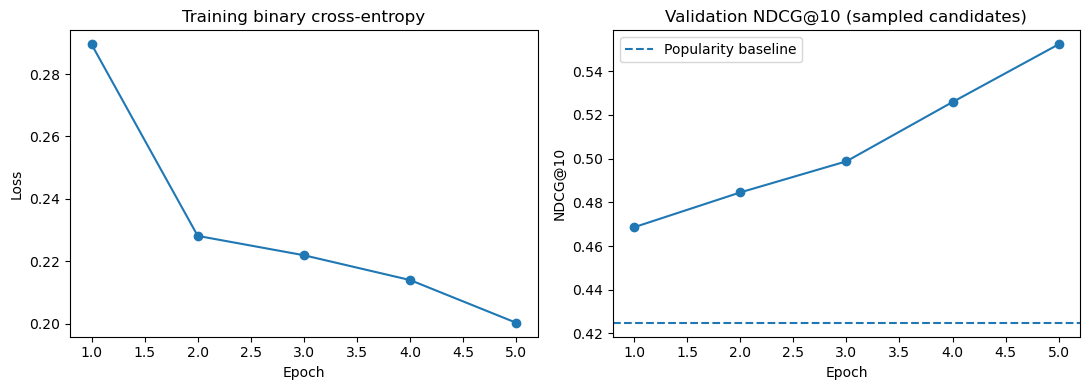

TEST — five positives + 2000 sampled unowned games per user
CAUTION: sampled-candidate results are NOT full-catalog recommendation metrics.


,recall@10,ndcg@10,hitrate@10,coverage@10,users_evaluated,mean_candidates_per_user
model,,,,,,
Popularity,0.3509,0.3265,0.8168,0.0628,786,2005.0
Neural Collaborative Filtering,0.4616,0.4608,0.9059,0.0861,786,2005.0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(training_df['epoch'], training_df['train_bce'], marker='o')
axes[0].set(title='Training binary cross-entropy', xlabel='Epoch', ylabel='Loss')
axes[1].plot(training_df['epoch'], training_df[f'val_ndcg@{TOP_K}'], marker='o')
axes[1].axhline(pop_val_report[f'ndcg@{TOP_K}'], linestyle='--', label='Popularity baseline')
axes[1].set(title='Validation NDCG@10 (sampled candidates)', xlabel='Epoch', ylabel='NDCG@10')
axes[1].legend()
plt.tight_layout()
plt.show()

ncf_test_report, ncf_test_users = compute_ranked_metrics(
    test_candidates, test_by_user, neural_scorer, TOP_K)

comparison = pd.DataFrame([
    {'model': 'Popularity', **pop_test_report},
    {'model': 'Neural Collaborative Filtering', **ncf_test_report},
]).set_index('model')
print(f'TEST — five positives + {TEST_NEGATIVE_CANDIDATES} sampled unowned games per user')
print('CAUTION: sampled-candidate results are NOT full-catalog recommendation metrics.')
display(comparison.round(4))

## 11. Activity-stratified results and diagnostic failures

With ~786 unusually active users, a single overall mean obscures variation. Split **existing users** into three equally sized activity groups by their number of *eligible training positives before capping*, then report mean Recall@10 and NDCG@10 within each group. This is a descriptive analysis, not a population-representative estimate. **Because each user's sampled training history is capped at 1,000, the activity grouping describes their original library size, not necessarily how many positives the neural model actually saw.**

**Failure cases** are examples with missed held-out games. They establish observable errors; hypotheses such as popularity bias and weak implicit labels must be described as explanations to test, rather than proven causes.

,activity_group,recall@10,ndcg@10,hitrate@10,model
0,Lower activity,0.3321,0.3222,0.7977,Popularity
1,Middle activity,0.3198,0.2850,0.7977,Popularity
2,Higher activity,0.4008,0.3723,0.8550,Popularity
3,Lower activity,0.4351,0.4358,0.8779,NCF
4,Middle activity,0.4489,0.4371,0.9122,NCF
5,Higher activity,0.5008,0.5097,0.9275,NCF


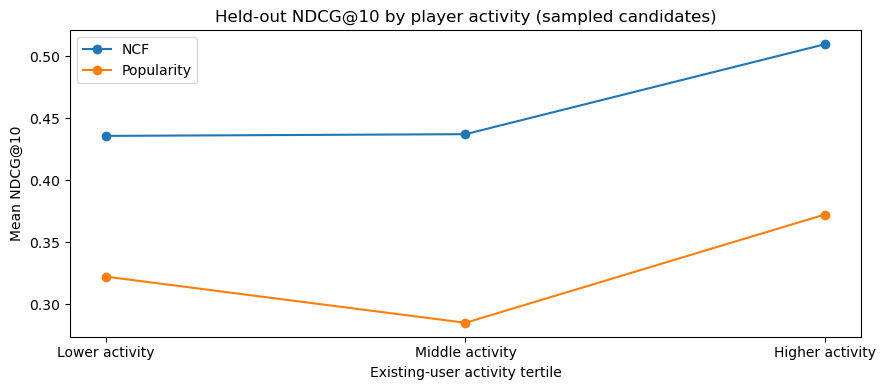

In [11]:
activity = pd.DataFrame({
    'user_idx': eligible_users,
    'full_training_positive_count': [full_train_counts[int(u)] for u in eligible_users],
})
activity['activity_group'] = pd.qcut(
    activity['full_training_positive_count'].rank(method='first'),
    q=3,
    labels=['Lower activity', 'Middle activity', 'Higher activity']
)

pop_group = pop_test_users.merge(activity, on='user_idx')
ncf_group = ncf_test_users.merge(activity, on='user_idx')
metric_columns = [f'recall@{TOP_K}', f'ndcg@{TOP_K}', f'hitrate@{TOP_K}']
activity_report = pd.concat([
    pop_group.groupby('activity_group', observed=True)[metric_columns].mean()
             .assign(model='Popularity'),
    ncf_group.groupby('activity_group', observed=True)[metric_columns].mean()
             .assign(model='NCF'),
]).reset_index()
display(activity_report.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
for model_name, subset in activity_report.groupby('model'):
    ax.plot(subset['activity_group'].astype(str), subset[f'ndcg@{TOP_K}'],
            marker='o', label=model_name)
ax.set(title='Held-out NDCG@10 by player activity (sampled candidates)',
       xlabel='Existing-user activity tertile', ylabel='Mean NDCG@10')
ax.legend()
plt.tight_layout()
plt.show()

## 12. Qualitative examples: successes and failures

Show a few existing users with their held-out games and top recommended games. `HIT` indicates that a title was one of the **five test positives**. This supports the required qualitative analysis without inventing explanations for specific recommendations. Steam user IDs are deliberately **not printed**.

In [12]:
def describe_user(u, top_items, limit=10):
    held = set(map(int, test_by_user[u]))
    print(f'Anonymized user index: {u} | Full training positives: {full_train_counts[u]}'
          f' | Test positives: {len(held)}')
    print('Held-out games: ' + '; '.join(display_name(int(i)) for i in test_by_user[u]))
    print('NCF top recommendations:')
    for rank, item in enumerate(top_items[:limit], start=1):
        marker = 'HIT' if int(item) in held else '   '
        print(f'  {rank:>2}. [{marker}] {display_name(int(item))}')

successful = ncf_test_users[ncf_test_users['hits'] > 0].sort_values('hits', ascending=False)
failed = ncf_test_users[ncf_test_users['hits'] == 0].sort_values('user_idx')

print('SUCCESS EXAMPLES')
if len(successful):
    for _, r in successful.head(2).iterrows():
        describe_user(int(r['user_idx']), r['top_items'])
        print()
else:
    print('No evaluated NCF user had a hit at 10; this is itself a failure finding.')

print('\nFAILURE EXAMPLES')
for _, r in failed.head(2).iterrows():
    describe_user(int(r['user_idx']), r['top_items'])
    print()

SUCCESS EXAMPLES
Anonymized user index: 118 | Full training positives: 5685 | Test positives: 5
Held-out games: Subject 13; Sirius; World's Dawn; Replica; Fly and Destroy
NCF top recommendations:
   1. [HIT] Subject 13
   2. [   ] Life is Strange 2
   3. [HIT] Fly and Destroy
   4. [HIT] World's Dawn
   5. [HIT] Sirius
   6. [   ] Reventure
   7. [HIT] Replica
   8. [   ] The Novelist
   9. [   ] Frisky Business
  10. [   ] KARAKARA

Anonymized user index: 617 | Full training positives: 1049 | Test positives: 5
Held-out games: 3 Stars of Destiny; Armed with Wings: Rearmed; Brushwood Buddies; Defend Your Crypt; Adventure World
NCF top recommendations:
   1. [HIT] Brushwood Buddies
   2. [HIT] 3 Stars of Destiny
   3. [HIT] Defend Your Crypt
   4. [HIT] Armed with Wings: Rearmed
   5. [   ] Adventure Apes and the Mayan Mystery
   6. [HIT] Adventure World
   7. [   ] Paranormal
   8. [   ] Voxel Blast
   9. [   ] Reigning Cats
  10. [   ] Gears 5


FAILURE EXAMPLES
Anonymized user index: 

## 13. Optional: full unowned-catalog ranking test

This is the most realistic test for the stated task: rank all game IDs the user is not recorded as owning, together with the five withheld positives. It is **much more difficult** than ranking among 2,000 sampled negative candidates. It is disabled for the first trial run; set `RUN_FULL_CATALOG_TEST=True` and run this cell for final reporting if your machine can handle the additional inference work.

If you submit sampled-candidate results without this step, clearly label them as sampled-candidate estimates rather than full-catalog Recall@10 or NDCG@10.

In [13]:
full_catalog_comparison = None
if RUN_FULL_CATALOG_TEST:
    print('Building full unowned-catalog test candidates ...')
    full_test_candidates = make_candidates(test_by_user, None, SEED + 33)
    full_pop_report, full_pop_users = compute_ranked_metrics(
        full_test_candidates, test_by_user, popularity_scorer, TOP_K)
    print('Scoring full catalog with NCF. This may take several minutes on CPU ...')
    full_ncf_report, full_ncf_users = compute_ranked_metrics(
        full_test_candidates, test_by_user, neural_scorer, TOP_K)
    full_catalog_comparison = pd.DataFrame([
        {'model': 'Popularity', **full_pop_report},
        {'model': 'Neural Collaborative Filtering', **full_ncf_report},
    ]).set_index('model')
    print('FULL UNOWNED-CATALOG TEST RESULTS')
    display(full_catalog_comparison.round(4))
else:
    print('Full-catalog test skipped. To run it, set RUN_FULL_CATALOG_TEST=True in Section 1.')

Building full unowned-catalog test candidates ...
Scoring full catalog with NCF. This may take several minutes on CPU ...
FULL UNOWNED-CATALOG TEST RESULTS


,recall@10,ndcg@10,hitrate@10,coverage@10,users_evaluated,mean_candidates_per_user
model,,,,,,
Popularity,0.0840,0.0763,0.3206,0.0201,786,35477.1247
Neural Collaborative Filtering,0.1817,0.1831,0.5483,0.0453,786,35477.1247


## 14. Save reproducibility artifacts and notebook results

Saves lightweight CSV/JSON files in `results/` and trained model weights in `models/` (not in Git by default). No raw Steam data is copied into these files. Existing-user ID mappings and exact per-user splits can be rebuilt from the raw dataset with seed 42; keep the local raw Parquet files unchanged.

**Commit the executed notebook, training source, and README/check-in report.** Do not claim metric values in the README until you have executed and inspected them.

In [14]:
training_df.to_csv(RESULTS_DIR / 'checkin2_training_history.csv', index=False)
comparison.to_csv(RESULTS_DIR / 'checkin2_sampled_test_metrics.csv')
activity_report.to_csv(RESULTS_DIR / 'checkin2_activity_groups.csv', index=False)
if full_catalog_comparison is not None:
    full_catalog_comparison.to_csv(RESULTS_DIR / 'checkin2_full_catalog_test_metrics.csv')

config_to_save = {
    'dataset': 'frankjc2022/steam-dataset',
    'positive_rule': 'playtime_forever > 0',
    'recommendation_scope': 'existing users; do not recommend known owned games',
    'random_seed': SEED,
    'n_users_original': n_users,
    'n_users_evaluated': len(eligible_users),
    'n_items_catalog': n_items,
    'minimum_positives': MIN_POSITIVES,
    'validation_positives_per_user': N_VAL_POSITIVES,
    'test_positives_per_user': N_TEST_POSITIVES,
    'max_training_positives_per_user': MAX_TRAIN_POSITIVES_PER_USER,
    'negative_ratio': NEGATIVE_RATIO,
    'embedding_dim': EMBEDDING_DIM,
    'hidden_dims': HIDDEN_DIMS,
    'dropout': DROPOUT,
    'learning_rate': LEARNING_RATE,
    'weight_decay': WEIGHT_DECAY,
    'epochs_max': EPOCHS,
    'best_epoch': best_epoch,
    'batch_size': BATCH_SIZE,
    'validation_negative_candidates_per_user': VAL_NEGATIVE_CANDIDATES,
    'sampled_test_negative_candidates_per_user': TEST_NEGATIVE_CANDIDATES,
    'full_catalog_test_performed': RUN_FULL_CATALOG_TEST,
    'device': str(DEVICE),
}
with (RESULTS_DIR / 'checkin2_config.json').open('w', encoding='utf-8') as f:
    json.dump(config_to_save, f, indent=2)

torch.save({
    'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
    'config': config_to_save,
    'item_appids': all_appids,
}, MODELS_DIR / 'ncf_checkin2.pt')

print('Saved training metrics/config in:', RESULTS_DIR)
print('Saved model weights in:', MODELS_DIR / 'ncf_checkin2.pt')

Saved training metrics/config in: /Users/robertgeorge/Desktop/DSAN Files/6600/dsan6600-finalproject/results
Saved model weights in: /Users/robertgeorge/Desktop/DSAN Files/6600/dsan6600-finalproject/models/ncf_checkin2.pt
